In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import bs
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
population = pd.read_parquet("Life_tables_data/weekly_population_all.parquet")
deaths = pd.read_parquet("Life_tables_data/deaths_weekly.parquet")
weather = pd.read_parquet("Life_tables_data/weekly_weather.parquet")

In [ ]:
def mortality_table(year, week, sex=None):
    pop = population.query("Year == @year and Week == @week").copy()
    d = deaths.query("Year == @year and Week == @week").copy()

    if sex in ("Male", "Female"):
        pop["Population"] = pop[sex]
        d = d[d["Sex"] == ("M" if sex == "Male" else "F")]
    else:
        pop["Population"] = pop["Total"]
        d = d.groupby("Age", as_index=False)["Deaths"].sum()

    table = pop[["Age", "Population"]].merge(d[["Age", "Deaths"]], on="Age", how="left")
    table["Deaths"] = table["Deaths"].fillna(0)
    table["Deaths"] = table["Deaths"].astype("int64")
    table["Population"] = table["Population"].round().astype("int64")
    table["remaining_population"] = table["Population"] - table["Deaths"]
    table["qx"] = table["Deaths"] / table["Population"]
    
    return table

In [ ]:
deaths = deaths.groupby(["Year", "Week", "Age"], as_index=False)["Deaths"].sum()
weather = weather.rename(columns={"year": "Year", "week": "Week"})

data = population.merge(deaths, on=["Year", "Week", "Age"], how="left")
data["Deaths"] = data["Deaths"].fillna(0).astype(int)
data["Population"] = data["Total"].round().astype(int)
data = data[data["Age"].between(20, 85)].copy()

weather_cols = ["TN", "TX", "UN", "UX"]
weather = weather.groupby(["Year", "Week"])[weather_cols].mean().reset_index()
data = data.merge(weather, on=["Year", "Week"], how="left")
data = data[data["Week"].between(18, 44)].copy()

# Baseline qx: 2019–2023
baseline_data = data[data["Year"].between(2019, 2023)]
qbase = baseline_data.groupby("Age").apply(lambda g: g["Deaths"].sum() / g["Population"].sum(), include_groups=False)

# Seasonal model: 10 years, 2014–2023
seasonal_train = data[data["Year"].between(2014, 2023)].copy()
seasonal_train["qbase"] = seasonal_train["Age"].map(qbase)

smooth_model = smf.glm(
    "Deaths ~ 0 + C(Age):bs(Week, df=6, degree=3, include_intercept=False, lower_bound=18, upper_bound=44)",
    data=seasonal_train, family=sm.families.Poisson(), offset=np.log(seasonal_train["Population"] * seasonal_train["qbase"])
).fit()

# Test: 2024–2025
test = data[data["Year"].between(2024, 2025)]
test["qx_observed"] = test["Deaths"] / test["Population"]
test["qx_baseline"] = test["Age"].map(qbase)

test["qx_smoothed"] = smooth_model.predict(test.assign(qbase=test["Age"].map(qbase)), 
        offset=np.log(test["Population"] * test["Age"].map(qbase))) / test["Population"]

data["qbase"] = data["Age"].map(qbase)
data["qx_smoothed"] = smooth_model.predict(data, offset=np.log(data["Population"] * data["qbase"])) / data["Population"]

# Fit the weather correction on 2014–2023
weather_train = data[data["Year"].between(2014, 2023)].dropna(subset= weather_cols + ["qx_smoothed"]).copy()

weather_model = smf.glm(f"Deaths ~ {' + '.join(weather_cols)}", data=weather_train, family=sm.families.Poisson(),
    offset=np.log(weather_train["Population"] * weather_train["qx_smoothed"])).fit()

test["qx_weather"] = weather_model.predict(test, offset=np.log(test["Population"] * test["qx_smoothed"])) / test["Population"]



BIAS BY AGE
     Observed  Baseline  Seasonal  Baseline bias (%)  Seasonal bias (%)
Age                                                                    
20        361    336.61    338.92              -6.76              -6.12
21        362    354.69    355.45              -2.02              -1.81
22        354    367.14    369.09               3.71               4.26
23        358    366.82    368.78               2.46               3.01
24        387    372.35    387.33              -3.79               0.09
25        378    372.70    381.41              -1.40               0.90
26        419    387.60    400.56              -7.49              -4.40
27        405    400.43    404.16              -1.13              -0.21
28        428    421.38    416.44              -1.55              -2.70
29        434    435.09    452.67               0.25               4.30
30        455    444.03    453.70              -2.41              -0.29
31        494    471.67    469.73              -4.5

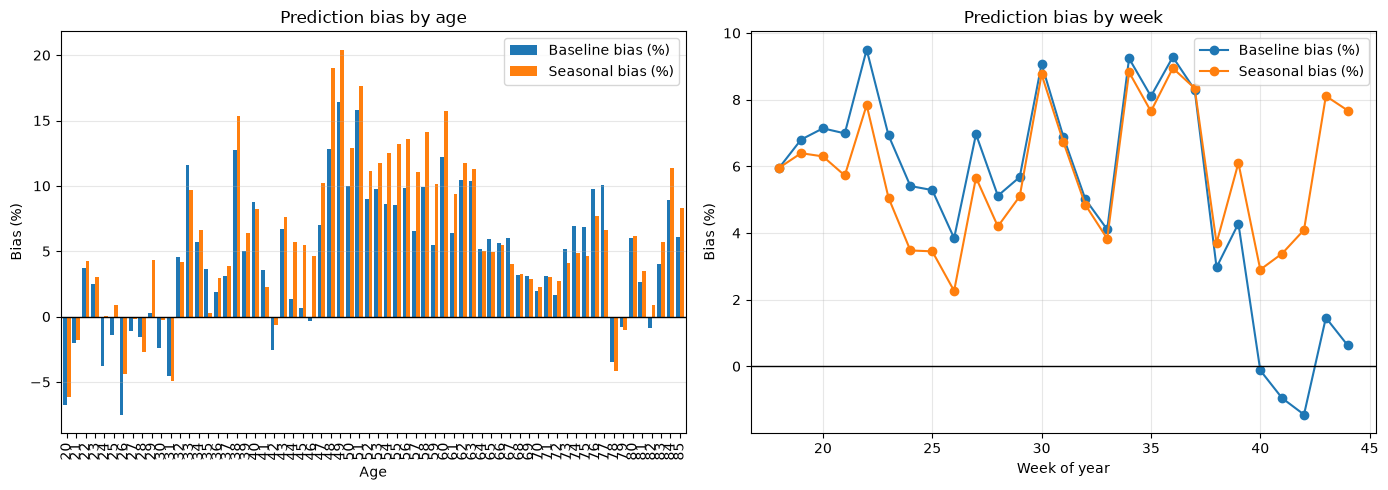

In [43]:
df = test.copy()

df["pred_baseline"] = df["qx_baseline"] * df["Population"]
df["pred_seasonal"] = df["qx_smoothed"] * df["Population"]

def bias_by(df, group):
    result = df.groupby(group).agg(
        Observed=("Deaths", "sum"),
        Baseline=("pred_baseline", "sum"),
        Seasonal=("pred_seasonal", "sum")
    )

    result["Baseline bias (%)"] = 100 * (result["Baseline"] - result["Observed"]) / result["Observed"].replace(0, np.nan)
    result["Seasonal bias (%)"] = 100 * (result["Seasonal"] - result["Observed"]) / result["Observed"].replace(0, np.nan)

    return result

age_bias = bias_by(df, "Age")
week_bias = bias_by(df, "Week")

print("\nBIAS BY AGE")
print(age_bias.round(2).to_string())

print("\nBIAS BY WEEK")
print(week_bias.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

age_bias[["Baseline bias (%)", "Seasonal bias (%)"]].plot(kind="bar", ax=axes[0], width=0.8)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Prediction bias by age")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Bias (%)")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend()

week_bias[["Baseline bias (%)", "Seasonal bias (%)"]].plot(ax=axes[1], marker="o")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Prediction bias by week")
axes[1].set_xlabel("Week of year")
axes[1].set_ylabel("Bias (%)")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

In [45]:
df = test.copy()
df["qx_observed"] = df["Deaths"] / df["Population"]
df["qx_baseline"] = df["qx_baseline"]
df["qx_seasonal"] = df["qx_smoothed"]

def metrics(g, pred):
    qx_obs = g["Deaths"].sum() / g["Population"].sum()
    qx_pred = (g[pred] * g["Population"]).sum() / g["Population"].sum()
    return pd.Series({
        "Observed qx": qx_obs,
        "Predicted qx": qx_pred,
        "Bias (%)": 100 * (qx_pred / qx_obs - 1),
        "MAE (qx)": (g[pred] - g["qx_observed"]).abs().mean(),
        "RMSE (qx)": np.sqrt(((g[pred] - g["qx_observed"]) ** 2).mean())
    })

for label, g in [
    ("All ages", df),
    ("Ages 20–32", df[df["Age"].between(20, 32)]),
    ("Ages 33+", df[df["Age"] >= 33])
]:
    print(f"\n{label}")
    print("Baseline:\n", metrics(g, "qx_baseline"))
    print("Seasonal:\n", metrics(g, "qx_seasonal"))


All ages
Baseline:
 Observed qx     0.000133
Predicted qx    0.000140
Bias (%)        5.176438
MAE (qx)        0.000016
RMSE (qx)       0.000032
dtype: float64
Seasonal:
 Observed qx     0.000133
Predicted qx    0.000141
Bias (%)        5.718315
MAE (qx)        0.000016
RMSE (qx)       0.000032
dtype: float64

Ages 20–32
Baseline:
 Observed qx     0.000010
Predicted qx    0.000010
Bias (%)       -1.526919
MAE (qx)        0.000003
RMSE (qx)       0.000004
dtype: float64
Seasonal:
 Observed qx     0.000010
Predicted qx    0.000010
Bias (%)       -0.296432
MAE (qx)        0.000003
RMSE (qx)       0.000004
dtype: float64

Ages 33+
Baseline:
 Observed qx     0.000164
Predicted qx    0.000172
Bias (%)        5.278721
MAE (qx)        0.000020
RMSE (qx)       0.000035
dtype: float64
Seasonal:
 Observed qx     0.000164
Predicted qx    0.000173
Bias (%)        5.810091
MAE (qx)        0.000020
RMSE (qx)       0.000035
dtype: float64
